# M4-offset HAWK-I/GRAAL empirical calibration

## Findings
The tile median Moffat FWHM is **0.3032 arcsec**. Identical-star comparison gives **+0.00077 arcsec** tile minus pawprint, with a spatial interval crossing zero. Crowding materially affects large-aperture noise. These products support bounded observational sensitivity experiments, not a unique instrumental calibration or dust truth.

## Context and methods
This executed evidence notebook reads completed measurements and independently reruns the integrity/numerical checks. The full source extraction was executed by the scripts and logs beside it. It does not retrain ML or open final-test science.

Assumptions: common28 raw exposures; already resampled stacks; signed finite-R2 growth curves; spatial rather than pixel bootstrap; no proof of each raw core's linear history. Full methods and official calibration links are in `protocol.md` and `scientific_report.md`. Use the existing phd Python environment.

In [1]:
from pathlib import Path
import sys, json, subprocess
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
O=Path.cwd()
if not (O/'PSF_summary.csv').exists():
    O=O/'analysis_results/hawki_m4off_20261028'
assert (O/'PSF_summary.csv').exists()
plt.rcParams.update({'figure.figsize':(10,4),'font.size':10})
s=pd.read_csv(O/'science_star_table.csv')
summary=pd.read_csv(O/'PSF_summary.csv')
pairs=pd.read_csv(O/'matched_stars_primary.csv')
assert pairs.gaia_id.nunique()==244


## Data and integrity
Original and small ancillary product provenance is recorded with hashes. All five science planes remain represented.

In [2]:
provenance=pd.read_csv(O/'fits_provenance.csv')
display(provenance[['extension','extname','mode','GRAAL','BUNIT','PHOTSYS','QCFLAG_digits','scale_arcsec','wcs_roundtrip_max_pixel']])
result=subprocess.run([sys.executable,str(O/'verify_results.py')],capture_output=True,text=True)
assert result.returncode==0,result.stderr
verification=json.loads((O/'verification.json').read_text())
display({k:v for k,v in verification.items() if k not in ['environment','independent_synthetic_fit']})

,extension,extname,mode,GRAAL,BUNIT,PHOTSYS,QCFLAG_digits,scale_arcsec,wcs_roundtrip_max_pixel
0,1,CHIP1.INT1,AO_IMG,GRAAL,ADU,VEGA,10000,0.106573,7.967174e-10
1,2,CHIP2.INT1,AO_IMG,GRAAL,ADU,VEGA,10000,0.106561,8.121788e-10
2,3,CHIP4.INT1,AO_IMG,GRAAL,ADU,VEGA,10000,0.106524,9.279120e-10
3,4,CHIP3.INT1,AO_IMG,GRAAL,ADU,VEGA,10000,0.106556,6.639311e-10
4,0,CHIP1.INT1,AO_IMG,GRAAL,ADU,VEGA,10000,0.106555,9.863470e-10


{'source_FITS_hashes_and_checksums': 'pass',
 'ancillary_hashes': 'pass',
 'stellar_tables_and_pair_identity': 'pass',
 'finite_aperture_EE_reference': 'pass',
 'positive_finite_PSF_and_covariance_kernels': 'pass',
 'PSD_noise_variance_mixtures': 'pass',
 'aperture_packing_and_WCS': 'pass',
 'previous_ML_freeze_receipt_sha256': '587aab56d39e6b29ad47f381c4b1440c8dd28eb52811ebc4ae3842b6fc220ce4',
 'scope': 'No ML training, tuning, injection, or final-science access in this task'}

## Spatial PSF and fit distributions
Intervals describe conditional medians across spatial cells. Detector2 has only four strict wing probes. Nonlinearity and quadrature floors are additional systematics. A synthetic0.22-arcsec, q0.8 case has a0.058 q error, showing optimizer/undersampling sensitivity.

,field,n_stars,n_wing_reliable,fwhm_arcsec_median,fwhm_arcsec_median_CI95_lo,fwhm_arcsec_median_CI95_hi,q_median,beta_median
0,pawprint1,158,18,0.2925,0.2823,0.3025,0.9164,2.8418
1,pawprint2,118,4,0.3200,0.3120,0.3290,0.8726,3.2780
2,pawprint3,164,19,0.2946,0.2906,0.3036,0.8743,3.0207
3,pawprint4,169,12,0.2982,0.2915,0.3033,0.8333,3.0240
4,tile0,356,45,0.3032,0.3005,0.3070,0.8742,3.0208


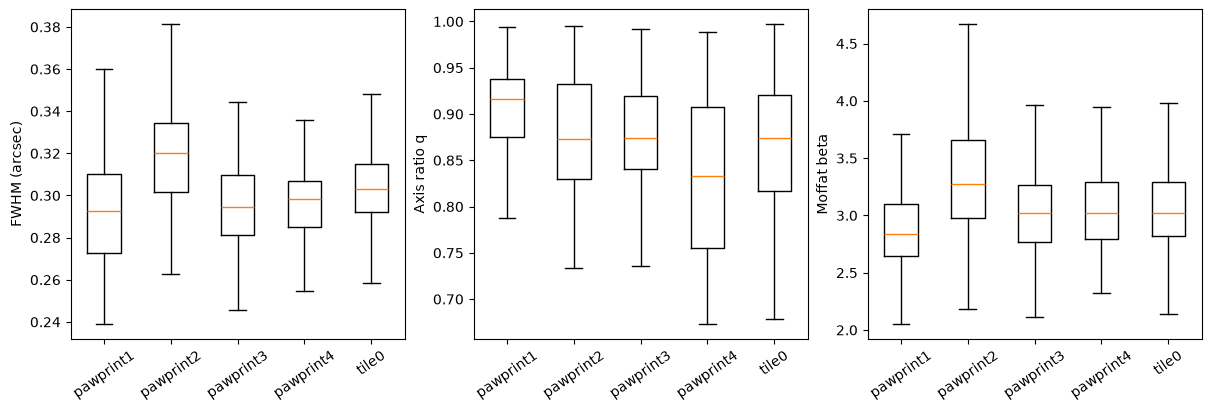

In [3]:
display(summary[['field','n_stars','n_wing_reliable','fwhm_arcsec_median','fwhm_arcsec_median_CI95_lo','fwhm_arcsec_median_CI95_hi','q_median','beta_median']].round(4))
good=s[s.primary_star]
fig,axes=plt.subplots(1,3,figsize=(12,4),layout='constrained')
for ax,col,label in zip(axes,['fwhm_arcsec','q','beta'],['FWHM (arcsec)','Axis ratio q','Moffat beta']):
    groups=list(good.groupby('field'))
    ax.boxplot([g[col].to_numpy() for _,g in groups],tick_labels=[f for f,_ in groups],showfliers=False)
    ax.set_ylabel(label);ax.tick_params(axis='x',rotation=35)
plt.show()

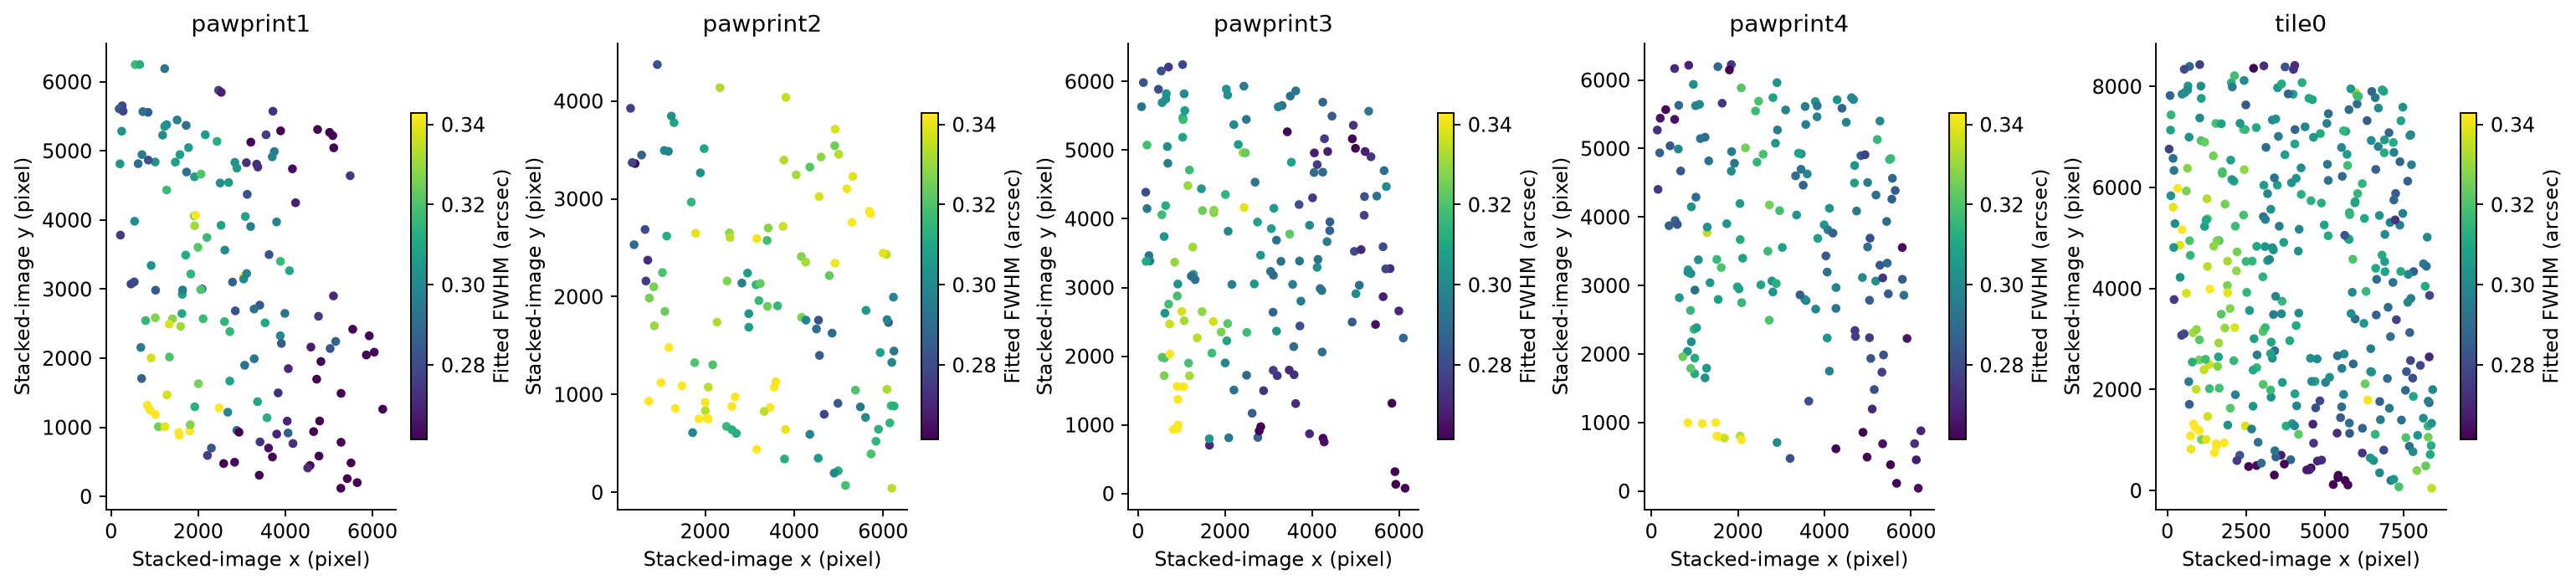

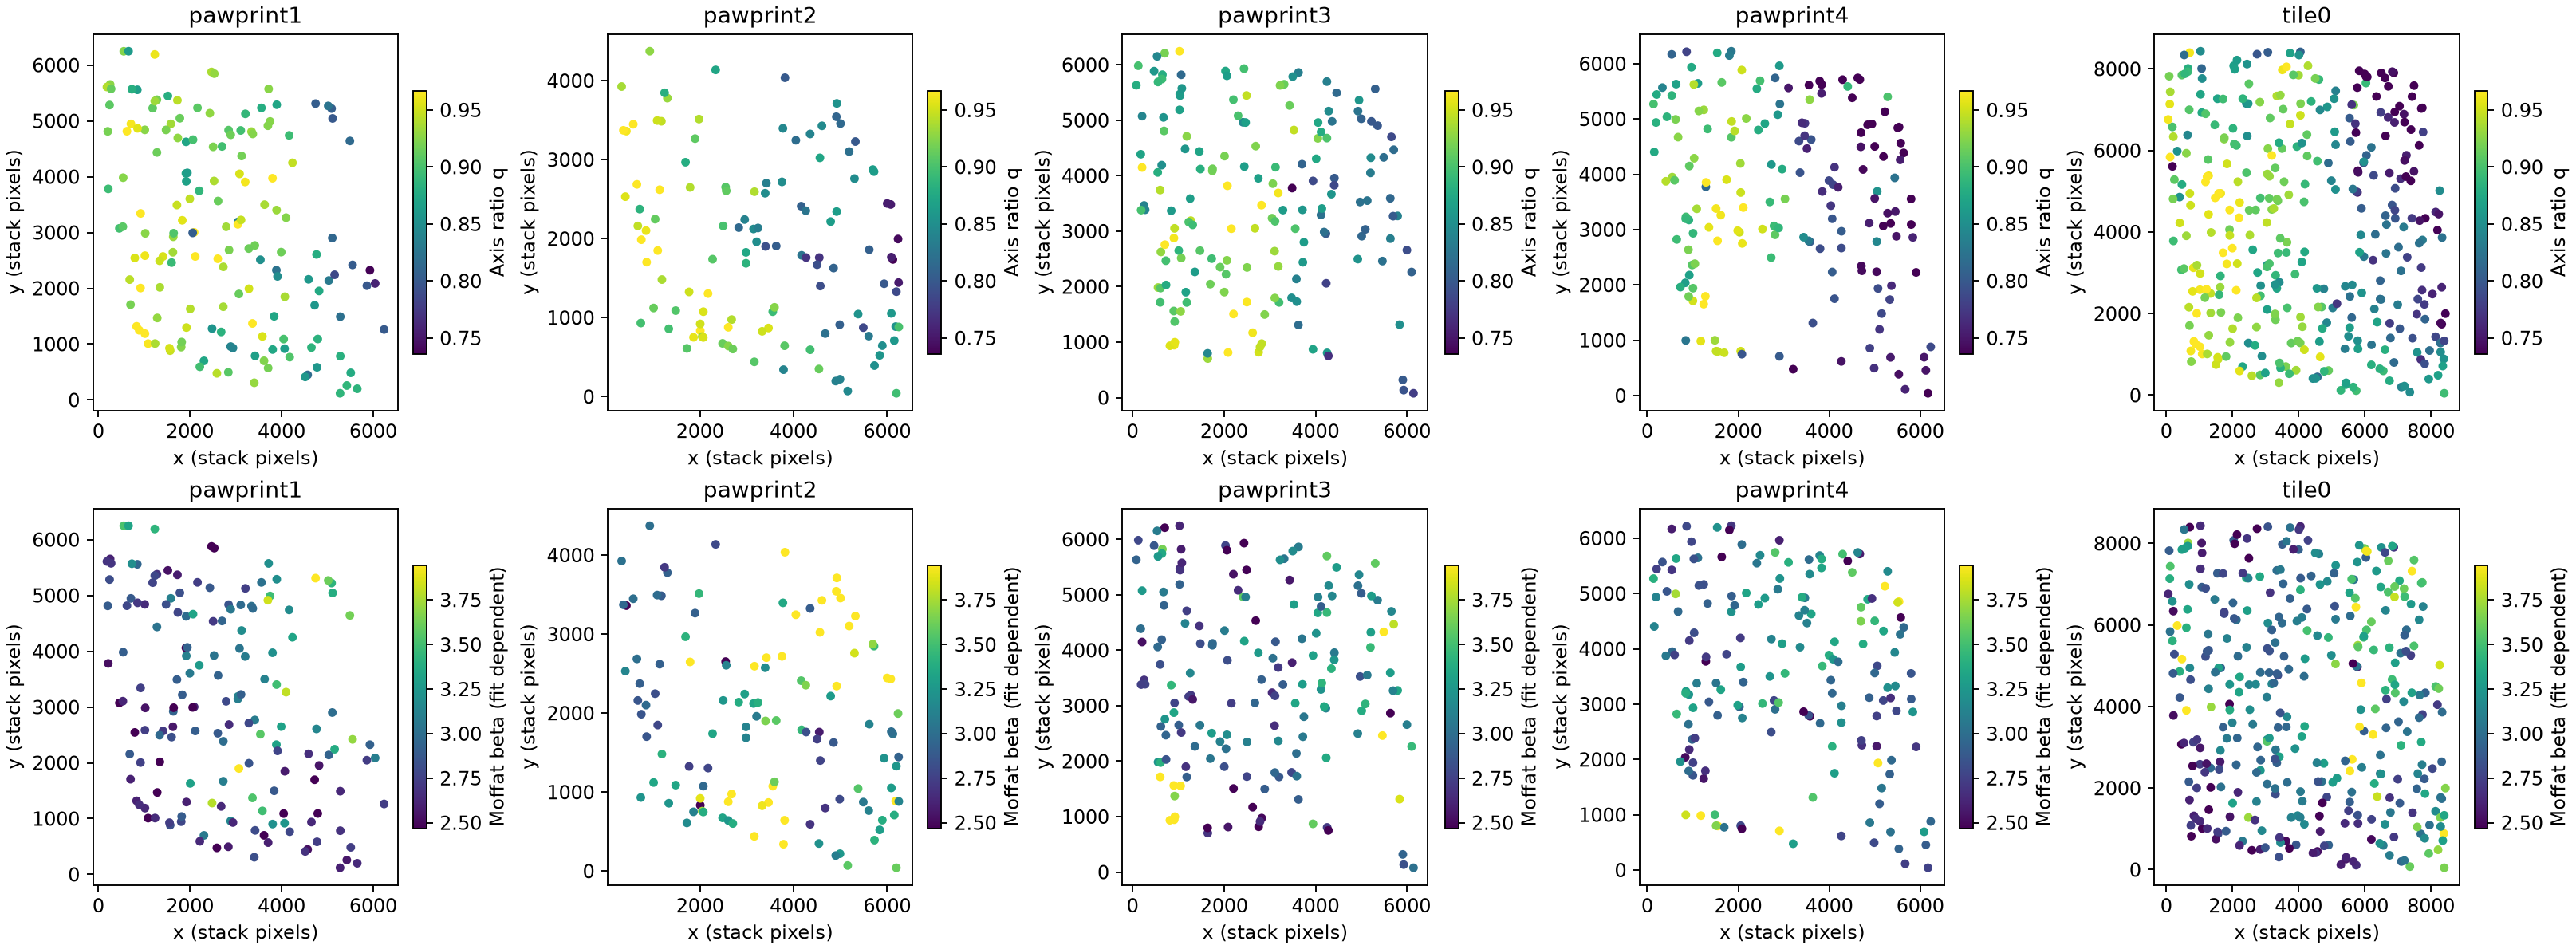

In [4]:
display(Image(filename=str(O/'figures/spatial_PSF_maps.png')))
display(Image(filename=str(O/'figures/spatial_shape_and_wings.png')))

## Identical stars across products
The 276 rows represent244 identities. Paired changes share photons; these are not independent observing realizations. Spatial intervals and estimator floors discourage precision global-processing claims.

,field,n_unique_stars,median,cluster_lo,cluster_hi
0,all_pawprints,244,0.000767,-0.000055,0.003291
8,pawprint1,87,0.002713,-0.000052,0.009855
16,pawprint2,47,-0.003542,-0.007905,0.000671
24,pawprint3,62,0.002838,0.000358,0.007940
32,pawprint4,80,0.001649,-0.002749,0.005488


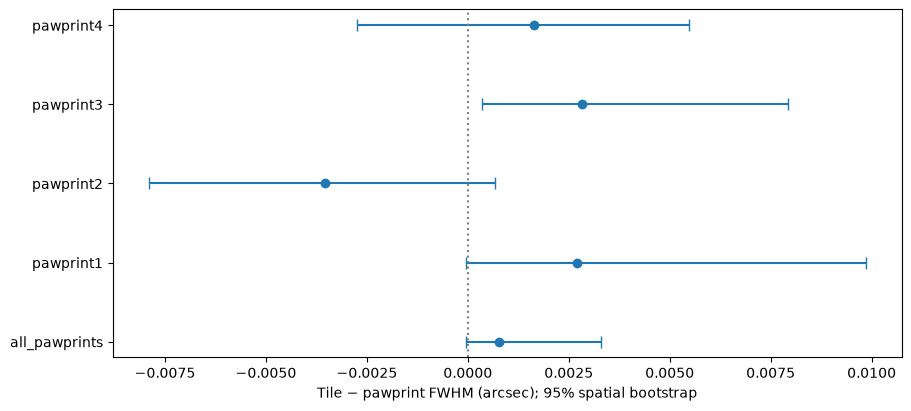

In [5]:
changes=pd.read_csv(O/'paired_changes.csv')
d=changes[changes.quantity=='delta_fwhm_arcsec'].copy()
display(d[['field','n_unique_stars','median','cluster_lo','cluster_hi']].round(6))
fig,ax=plt.subplots(figsize=(9,4),layout='constrained')
y=np.arange(len(d));ax.errorbar(d['median'],y,xerr=np.vstack([d['median']-d.cluster_lo,d.cluster_hi-d['median']]),fmt='o',capsize=4)
ax.axvline(0,color='gray',ls=':');ax.set(yticks=y,yticklabels=d.field,xlabel='Tile − pawprint FWHM (arcsec); 95% spatial bootstrap')
plt.show()

## Finite empirical wings
Circular EE is relative to2arcsec. Cleaner detected neighbours and annular-scatter cuts reduce, but do not remove, unresolved-star contamination. Moffat tails beyond this radius are fitted extrapolations.

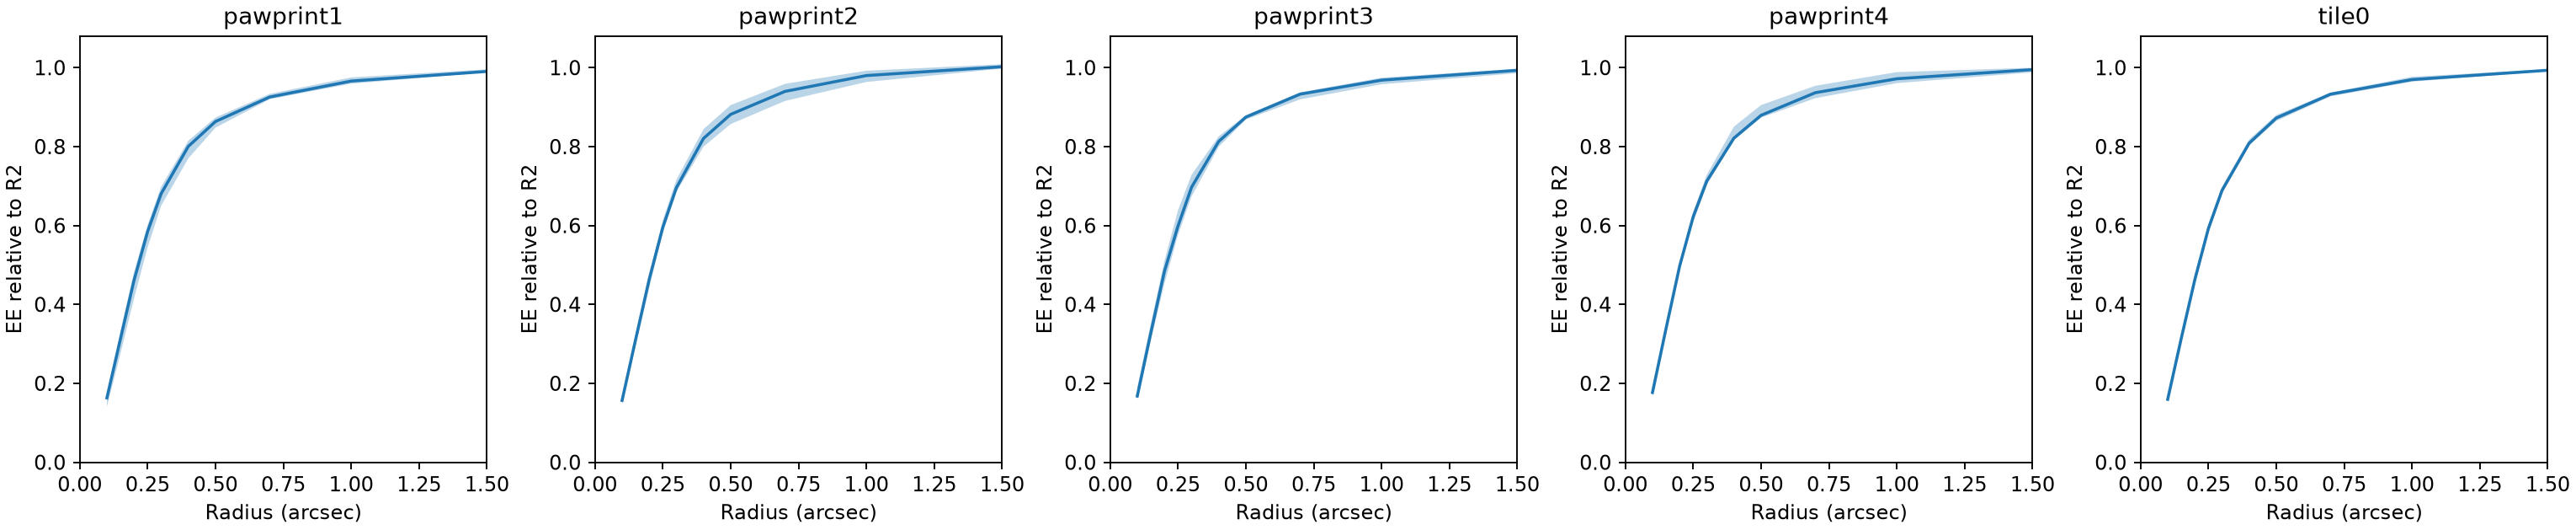

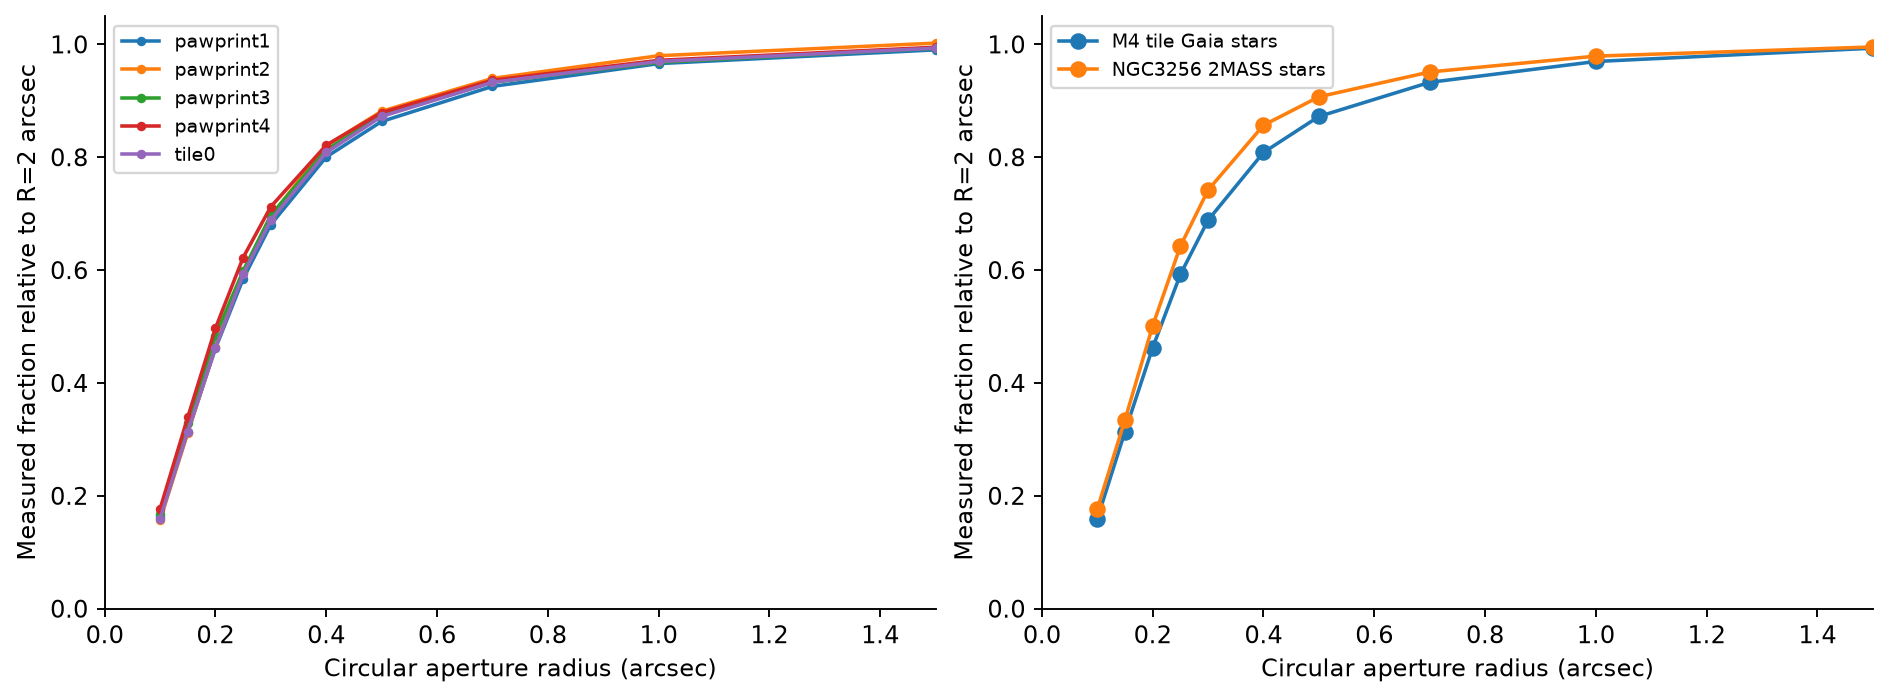

,field,delta_fwhm_arcsec,delta_q,delta_beta
0,pawprint1,0.00066,-0.00000,0.05492
1,pawprint2,0.00083,-0.00006,0.12690
2,pawprint3,0.00057,0.00001,0.08775
3,pawprint4,0.00039,-0.00002,0.05185
4,tile0,0.00088,-0.00005,0.11667


,truth_FWHM_arcsec,truth_beta,truth_q,delta_FWHM_arcsec,fractional_FWHM_bias
0,0.22,2.5,0.8,0.00139,0.00634
1,0.22,2.5,1.0,0.00180,0.00818
2,0.22,4.0,0.8,0.00166,0.00754
3,0.22,4.0,1.0,0.00163,0.00741
4,0.30,2.5,0.8,0.00137,0.00458
5,0.30,2.5,1.0,0.00135,0.00449
6,0.30,4.0,0.8,0.00123,0.00411
7,0.30,4.0,1.0,0.00121,0.00402
8,0.40,2.5,0.8,0.00105,0.00261
9,0.40,2.5,1.0,0.00102,0.00255


In [6]:
display(Image(filename=str(O/'figures/EE_spatial_bootstrap.png')))
display(Image(filename=str(O/'figures/empirical_encircled_energy.png')))
display(pd.read_csv(O/'fit_window_summary.csv').round(5))
quad=pd.read_csv(O/'quadrature_sensitivity.csv')
display(quad[['truth_FWHM_arcsec','truth_beta','truth_q','delta_FWHM_arcsec','fractional_FWHM_bias']].round(5))

## Finite-growth model sensitivity
A core+Gaussian halo fits finite outer light missed by the single Moffat. It is a phenomenological stress model; detector2 has sparse support and a boundary optimum. Halo fractions are not uniquely measured physical flux fractions.

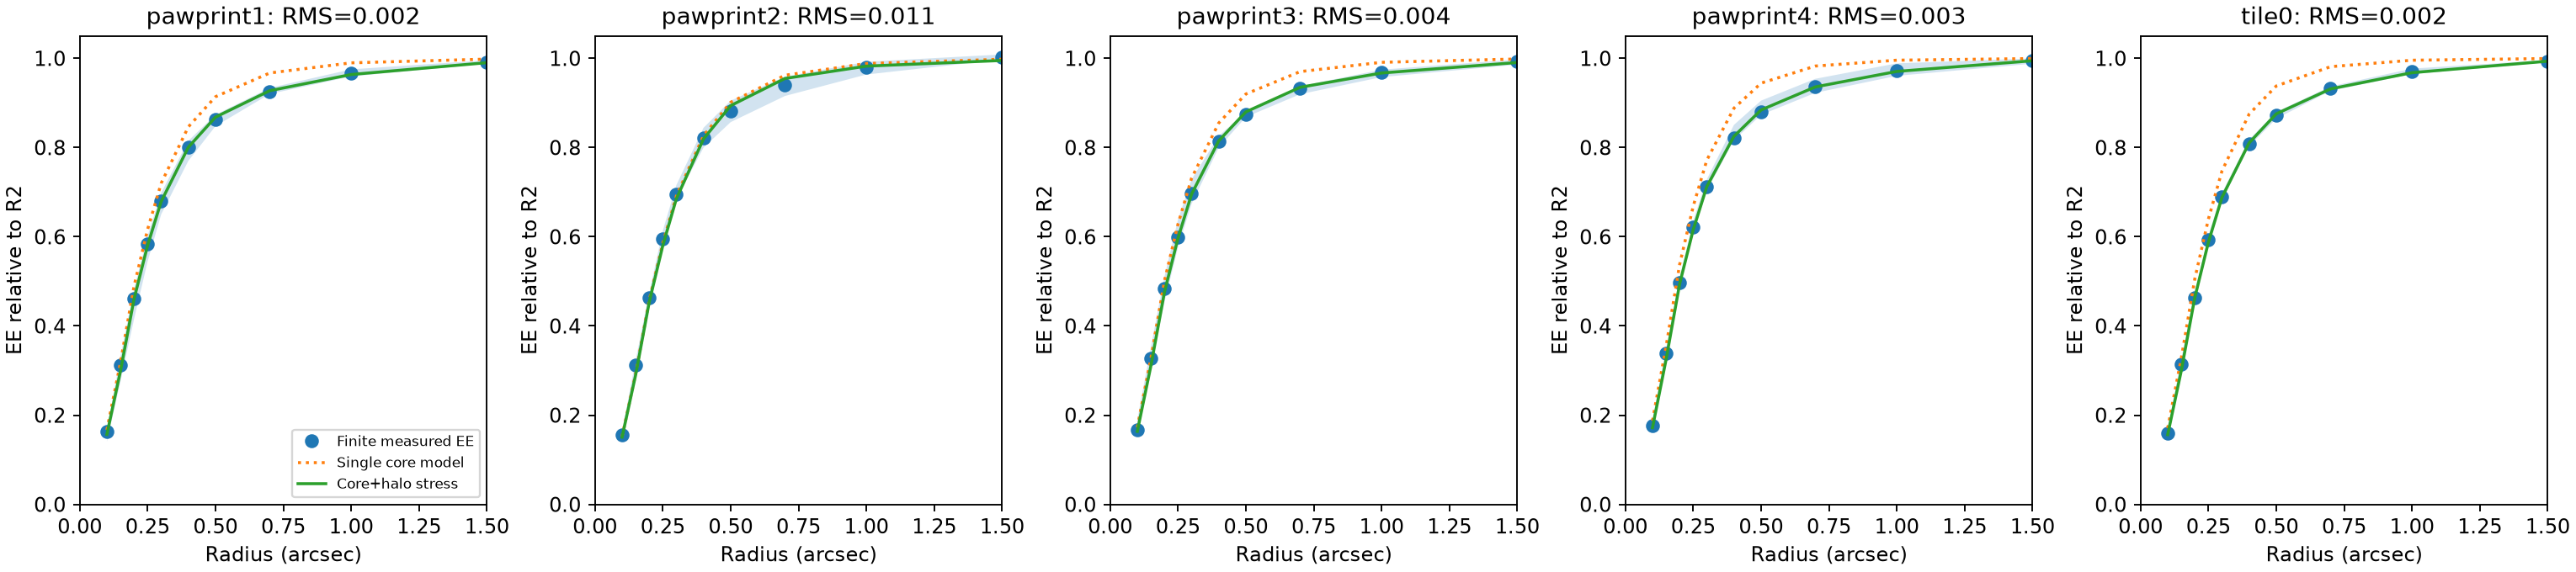

,field,halo_FWHM_arcsec,halo_fraction_extrapolated_total,finite_EE_RMS,n_clean_wing_stars
27,pawprint1,1.85,0.0657,0.0025,18
101,pawprint2,3.00,0.0133,0.0105,4
131,pawprint3,1.95,0.0568,0.0038,19
173,pawprint4,1.50,0.0895,0.0034,12
225,tile0,1.55,0.0922,0.0023,45


In [7]:
display(Image(filename=str(O/'figures/growth_curve_model_sensitivity.png')))
growth=pd.read_csv(O/'sensitivity_models/finite_growth_model_grid.csv')
display(growth[growth.best][['field','halo_FWHM_arcsec','halo_fraction_extrapolated_total','finite_EE_RMS','n_clean_wing_stars']].round(4))

## Background covariance and crowding
The same-estimator comparison is between different scenes, not matched depths. R32 void apertures are too sparse for calibration. Region intervals omit mask/sky systematics and do not count overlapping centers as independent.

,field,rho_x1,rho_y1,excess_R2,excess_R4,excess_R8,excess_R16
0,M4 tile,0.371,0.354,1.732,2.639,4.596,6.533
1,NGC3256 same estimator,0.265,0.292,1.410,1.655,1.878,1.978


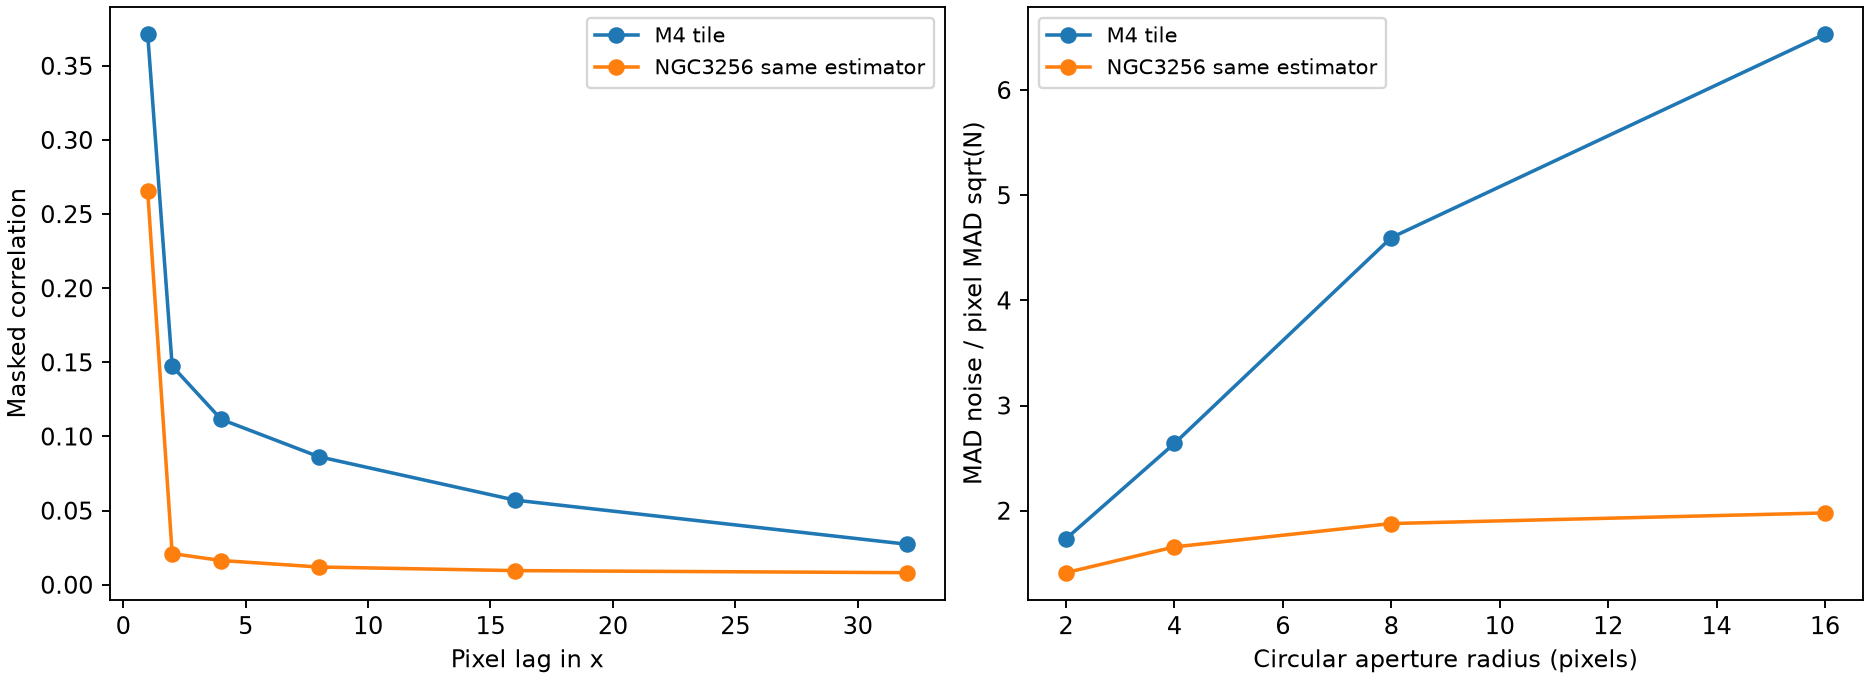

,radius_pixels,n_regions,n_geometrically_nonoverlapping_lower_bound,median,p16,p84,median_region_boot_CI95_lo,median_region_boot_CI95_hi,calibration_accepted
44,2,9,4181,1.732,1.525,1.996,1.504,1.998,True
45,4,9,3274,2.639,2.117,3.132,2.082,3.206,True
46,8,9,1616,4.596,3.163,4.961,2.961,5.005,True
47,16,9,385,6.533,4.573,7.325,4.489,7.446,True
48,32,6,22,3.781,1.186,4.501,1.112,4.508,False


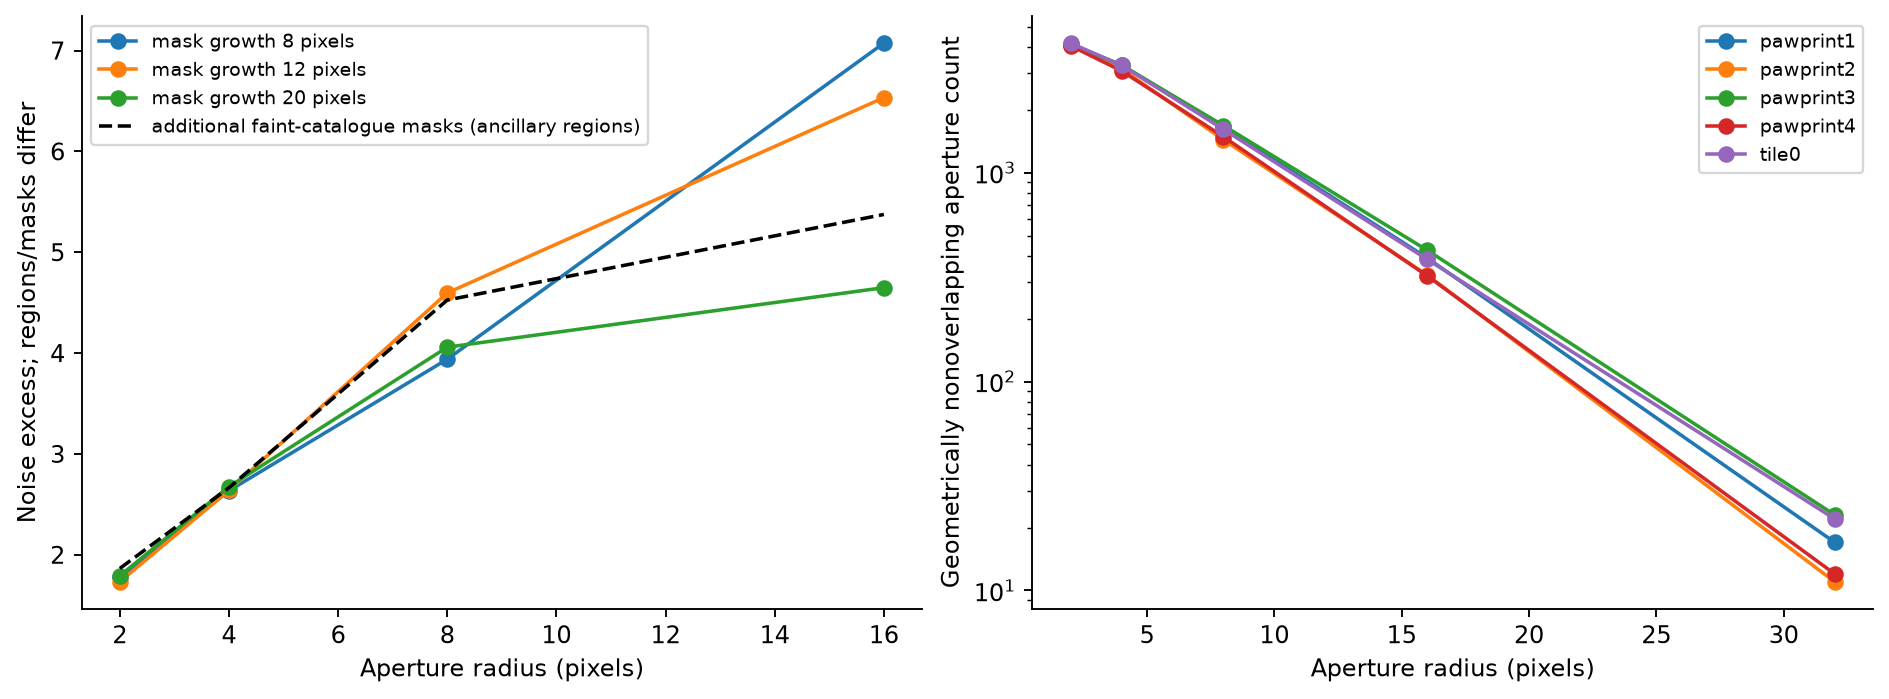

In [8]:
display(pd.read_csv(O/'same_operator_noise_summary.csv').round(3))
display(Image(filename=str(O/'figures/NGC3256_same_operator_noise.png')))
u=pd.read_csv(O/'aperture_noise_uncertainty.csv')
display(u[(u.field=='tile0')&(u.kind=='grid')][['radius_pixels','n_regions','n_geometrically_nonoverlapping_lower_bound','median','p16','p84','median_region_boot_CI95_lo','median_region_boot_CI95_hi','calibration_accepted']].round(3))
display(Image(filename=str(O/'figures/crowding_and_aperture_reliability.png')))

## Model checks and handoff
Use local-correlation kernels separately from the broader total-background mixture. The latter has retained13–37% response discrepancies and includes confusion. Amplitude and ULTIMATE instrument specifications require separate calibration.

In [9]:
checks=pd.read_csv(O/'sensitivity_models/local_noise_simulation_checks.csv')
checks['absolute_difference']=abs(checks.realized-checks.predicted)
display(checks.groupby('field').absolute_difference.max().round(5))
models=json.loads((O/'sensitivity_models/noise_family.json').read_text())
display(pd.DataFrame([{'field':m['field'],'maximum_response_misfit':m['max_fractional_response_error'],'scope':m['calibration_status']} for m in models]))
assert not good.flat_core_flag.any()
assert summary.n_stars.sum()==965
print('All notebook checks passed. Previous ML frozen-artifact receipt:',verification['previous_ML_freeze_receipt_sha256'])

field
pawprint1    0.00880
pawprint2    0.01648
pawprint3    0.00960
pawprint4    0.02746
tile0        0.00306
Name: absolute_difference, dtype: float64

,field,maximum_response_misfit,scope
0,pawprint1,0.260965,Approximate total-background stress only; resp...
1,pawprint2,0.268447,Approximate total-background stress only; resp...
2,pawprint3,0.369880,Approximate total-background stress only; resp...
3,pawprint4,0.308026,Approximate total-background stress only; resp...
4,tile0,0.131263,Approximate total-background stress only; resp...


All notebook checks passed. Previous ML frozen-artifact receipt: 587aab56d39e6b29ad47f381c4b1440c8dd28eb52811ebc4ae3842b6fc220ce4


## Interpretation
Measured HAWK-I core quality spans roughly0.29–0.32arcsec. No robust global same-star processing shift is demonstrated. Spatial ellipticity and wings should be preserved jointly. Background variance is strongly aperture- and mask-dependent in this crowded field. The analytic wing continuation and total-background mixture are explicit sensitivity assumptions.

See `scientific_report.md` for conclusions, `sensitivity_models/README.md` for model use, and `README.md` for offline reproduction. Future calibration needs include uncrowded blank sky/wings, per-source raw-linearity histories, absolute photometry/astrometry and target-instrument spectral/PSF data. No0.2arcsec ULTIMATE measurement, dust truth or new ML validation is claimed.